5 秒後截圖，請切換到 Chrome 小恐龍
偵測線截圖完成！
Retina 倍率： 2.0 2.0


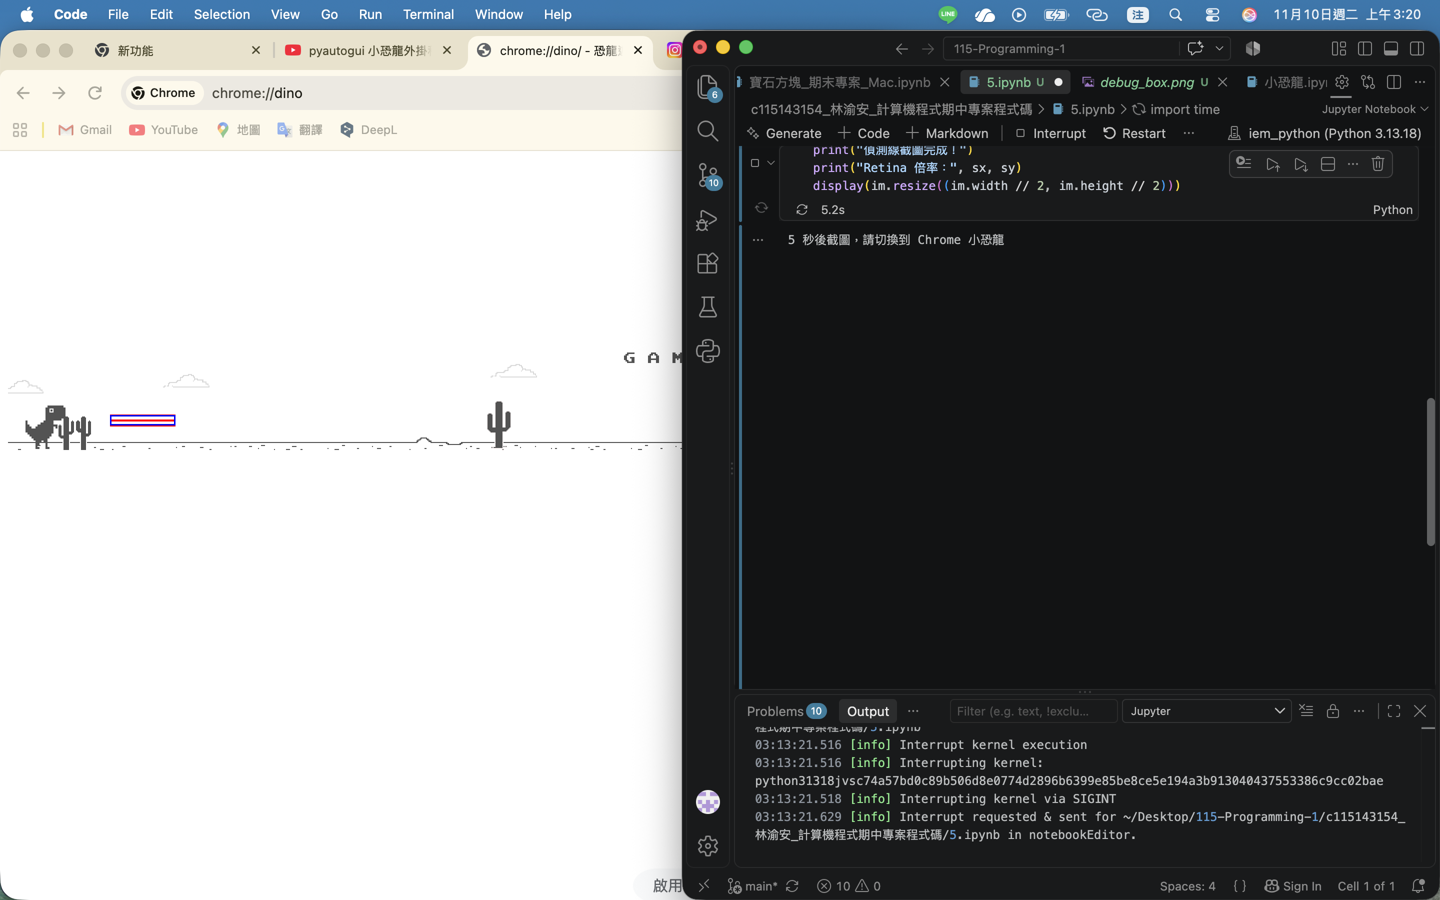

In [8]:
import time
import pyautogui as pyg
from PIL import ImageDraw
from IPython.display import display

# 目前使用的偵測座標
START_X = 110
END_X = 175
DETECT_Y = [415, 420, 425]

print("5 秒後截圖，請切換到 Chrome 小恐龍")
time.sleep(5)

im = pyg.screenshot().convert("RGB")

# Retina 倍率
sw, sh = pyg.size()
sx = im.width / sw
sy = im.height / sh

draw = ImageDraw.Draw(im)

# 畫出偵測範圍
for y in DETECT_Y:
    draw.line(
        (
            int(START_X * sx),
            int(y * sy),
            int(END_X * sx),
            int(y * sy)
        ),
        fill="red",
        width=4
    )

# 畫出外框
draw.rectangle(
    (
        int(START_X * sx),
        int(min(DETECT_Y) * sy),
        int(END_X * sx),
        int(max(DETECT_Y) * sy)
    ),
    outline="blue",
    width=3
)

im.save("dino_lines_debug.png")

print("偵測線截圖完成！")
print("Retina 倍率：", sx, sy)
display(im.resize((im.width // 2, im.height // 2)))

In [12]:
import time
import numpy as np
import pyautogui as pyg

pyg.FAILSAFE = True
pyg.PAUSE = 0

# 偵測仙人掌的範圍
START_X = 110
END_X = 175
TOP_Y = 410
BOTTOM_Y = 430

sw, sh = pyg.size()
shot = pyg.screenshot()

sx = shot.width / sw
sy = shot.height / sh

box = (
    int(START_X * sx),
    int(TOP_Y * sy),
    int(END_X * sx),
    int(BOTTOM_Y * sy)
)

jump_count = 0
last_jump = 0
obstacle_active = False

print("5 秒後開始，請切換到 Chrome")
time.sleep(5)

pyg.press("space")

try:
    while True:
        im = pyg.screenshot().convert("RGB")
        region = np.array(im.crop(box))

        # 偵測深色仙人掌
        dark = np.max(region, axis=2) < 120
        dark_count = int(np.sum(dark[::4, ::4]))

        now = time.time()

        # 偵測到新的仙人掌
        if dark_count >= 5 and not obstacle_active:
            if now - last_jump > 0.4:
                pyg.press("space")

                jump_count += 1
                last_jump = now
                obstacle_active = True

                print("第", jump_count, "次跳躍")

        # 仙人掌完全離開偵測區
        elif dark_count < 5:
            obstacle_active = False

except KeyboardInterrupt:
    print("程式停止，總跳躍次數：", jump_count)


5 秒後開始，請切換到 Chrome
第 1 次跳躍
第 2 次跳躍
程式停止，總跳躍次數： 2


In [13]:
import time
import numpy as np
import pyautogui as pyg

pyg.FAILSAFE = True
pyg.PAUSE = 0

# 偵測範圍
START_X = 110
END_X = 230
TOP_Y = 410
BOTTOM_Y = 430

# 仙人掌靠近這個 X 座標才跳
JUMP_X = 145

sw, sh = pyg.size()
shot = pyg.screenshot()
sx = shot.width / sw
sy = shot.height / sh

box = (
    int(START_X * sx),
    int(TOP_Y * sy),
    int(END_X * sx),
    int(BOTTOM_Y * sy)
)

jump_count = 0
last_jump = 0
obstacle_active = False

print("5 秒後開始，請切換到 Chrome")
time.sleep(5)

pyg.press("space")

try:
    while True:
        im = pyg.screenshot().convert("RGB")
        region = np.array(im.crop(box))

        # 找出仙人掌的深色像素
        dark = np.max(region, axis=2) < 120

        # 每個 X 座標的深色像素數量
        column_count = np.sum(dark, axis=0)

        # 找出有仙人掌的 X 位置
        positions = np.where(column_count >= 3)[0]

        if len(positions) > 0:
            obstacle_x = START_X + positions[0] / sx

            # 仙人掌接近跳躍位置
            if obstacle_x <= JUMP_X and not obstacle_active:
                if time.time() - last_jump > 0.4:
                    pyg.press("space")
                    jump_count += 1
                    last_jump = time.time()
                    obstacle_active = True

                    print("第", jump_count, "次跳躍")

        else:
            obstacle_active = False

except KeyboardInterrupt:
    print("程式停止，總跳躍次數：", jump_count)


5 秒後開始，請切換到 Chrome
第 1 次跳躍
程式停止，總跳躍次數： 1
